# PSO Seminar: objective functions, swarm simulation and ω experiments

Notebook of **Member 2 (TV2)**, seminar S01 *Particle Swarm Optimization*.

| Part | Content | Prompt |
|---|---|---|
| 1 | Objective functions, `pso()` implementation, quick test | 2.1 |
| 2 | Hand-calculation check (1-D example) and 5-particle × 5-iteration simulation on Sphere | 2.2 |
| 3 | Three inertia-weight settings × 5 seeds on Sphere and Rastrigin, `results_pso.csv`, convergence plots | 2.3 |

All parameters follow the team's shared parameter table. Run the cells from top to bottom (Runtime > Run all in Colab).

## 0. Setup

In [1]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Output folders (created next to the notebook, or in /content when running on Colab)
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)

# Shared parameters of the team (do not change without updating the shared table)
BOUNDS = (-5.12, 5.12)   # search domain for every dimension
DIM = 2                  # number of decision variables
VMAX = 10.24            # velocity limit |v| <= VMAX (= domain width; Vmax = Xmax rule of Poli et al. 2007)
W_DEFAULT, C1_DEFAULT, C2_DEFAULT = 0.7, 1.5, 1.5
N_PARTICLES, N_ITER = 20, 100
SEEDS = [0, 1, 2, 3, 4]
CONFIGS = {"A": 0.4, "B": 0.7, "C": 0.9}   # inertia weight of each configuration

## 1. Objective functions and PSO (prompt 2.1)

In [2]:
def sphere(X):
    # Sphere: f(x) = sum_i x_i^2. Accepts one point (d,) or a batch (n, d).
    X = np.asarray(X, dtype=float)
    return np.sum(X ** 2, axis=-1)


def rastrigin(X):
    # Rastrigin: f(x) = 10 n + sum_i (x_i^2 - 10 cos(2 pi x_i)). Many local minima, global minimum 0 at the origin.
    X = np.asarray(X, dtype=float)
    n = X.shape[-1]
    return 10 * n + np.sum(X ** 2 - 10 * np.cos(2 * np.pi * X), axis=-1)


FUNCTIONS = {"Sphere": sphere, "Rastrigin": rastrigin}

# Sanity checks: both functions are 0 at the global minimum (0, 0)
assert sphere([0.0, 0.0]) == 0.0
assert abs(rastrigin([0.0, 0.0])) < 1e-12
print("sphere(0,0) =", sphere([0.0, 0.0]), "| rastrigin(0,0) =", rastrigin([0.0, 0.0]))
print("sphere(1,2) =", sphere([1.0, 2.0]), "| rastrigin(1,1) =", rastrigin([1.0, 1.0]))

sphere(0,0) = 0.0 | rastrigin(0,0) = 0.0
sphere(1,2) = 5.0 | rastrigin(1,1) = 2.0


**Giải thích (VI):** hai hàm nhận một điểm hoặc cả ma trận điểm (mỗi hàng là một hạt), nên một lần gọi đánh giá được cả bầy. Ô kiểm tra xác nhận cả hai hàm bằng 0 tại (0, 0). Thêm hai giá trị dễ bấm máy: sphere(1, 2) = 1 + 4 = 5; rastrigin(1, 1) = 20 + 2·(1 − 10·cos 2π) = 20 − 18 = 2.

In [3]:
def pso(func, n_particles=N_PARTICLES, n_iter=N_ITER, w=W_DEFAULT, c1=C1_DEFAULT, c2=C2_DEFAULT,
        bounds=BOUNDS, vmax=VMAX, seed=0, dim=DIM, log_states=False, clamp=True):
    # Global-best PSO (gbest topology), minimisation.
    #   v(t+1) = w v(t) + c1 r1 (pbest - x(t)) + c2 r2 (gbest - x(t))
    #   x(t+1) = x(t) + v(t+1)
    # r1, r2 ~ U(0, 1) are drawn per particle, per dimension, per iteration.
    rng = np.random.default_rng(seed)
    lo, hi = bounds

    # Initialisation: positions uniform in the domain, velocities uniform in [-vmax, vmax]
    x = rng.uniform(lo, hi, size=(n_particles, dim))
    v = rng.uniform(-vmax, vmax, size=(n_particles, dim))
    f = func(x)
    evaluations = n_particles

    pbest, pbest_f = x.copy(), f.copy()          # personal bests
    g = int(np.argmin(pbest_f))
    gbest, gbest_f = pbest[g].copy(), float(pbest_f[g])   # global best

    history = [{"iteration": 0, "evaluations": evaluations, "best_fitness": gbest_f}]
    states = []
    if log_states:
        states.append({"iteration": 0, "x": x.copy(), "v": v.copy(), "f": f.copy(),
                       "pbest": pbest.copy(), "pbest_f": pbest_f.copy(),
                       "gbest": gbest.copy(), "gbest_f": gbest_f, "r1": None, "r2": None})

    for t in range(1, n_iter + 1):
        r1 = rng.random((n_particles, dim))
        r2 = rng.random((n_particles, dim))
        gbest_used = gbest.copy()                 # gbest of the previous iteration drives this update

        # Velocity update (inertia + cognitive + social), then clamp to [-vmax, vmax]
        v = w * v + c1 * r1 * (pbest - x) + c2 * r2 * (gbest_used - x)
        if clamp:                                 # clamp=False: vmax only sets the initial velocity range
            v = np.clip(v, -vmax, vmax)

        # Position update with the NEW velocity, then clip to the domain
        x = np.clip(x + v, lo, hi)

        f = func(x)
        evaluations += n_particles

        # Update personal bests where the new position is strictly better
        improved = f < pbest_f
        pbest[improved] = x[improved]
        pbest_f[improved] = f[improved]

        # Update global best
        g = int(np.argmin(pbest_f))
        if pbest_f[g] < gbest_f:
            gbest, gbest_f = pbest[g].copy(), float(pbest_f[g])

        history.append({"iteration": t, "evaluations": evaluations, "best_fitness": gbest_f})
        if log_states:
            states.append({"iteration": t, "x": x.copy(), "v": v.copy(), "f": f.copy(),
                           "pbest": pbest.copy(), "pbest_f": pbest_f.copy(),
                           "gbest": gbest.copy(), "gbest_f": gbest_f,
                           "r1": r1.copy(), "r2": r2.copy(), "gbest_used": gbest_used})

    return {"history": pd.DataFrame(history), "best_x": gbest, "best_f": gbest_f,
            "evaluations": evaluations, "states": states}

**Giải thích (VI):**
- Dòng `v = w * v + c1 * r1 * (pbest - x) + c2 * r2 * (gbest_used - x)` chính là công thức vận tốc chung: quán tính `w·v`, thành phần nhận thức `c1·r1·(pbest − x)`, thành phần xã hội `c2·r2·(gbest − x)`.
- Dòng `x = np.clip(x + v, lo, hi)` là công thức vị trí với **vận tốc mới** v(t+1), sau đó cắt về miền tìm kiếm.
- `r1`, `r2` sinh mới cho từng hạt, từng chiều, mỗi vòng. Bộ sinh số ngẫu nhiên dùng `seed`, nên cùng seed thì kết quả giống hệt.
- Mỗi vòng gọi hàm mục tiêu đúng `n_particles` lần; với 20 hạt và 100 vòng tổng là 20 + 20 × 100 = 2020 lần, khớp ngân sách chung.

In [4]:
def run_experiments(functions, configs, seeds, c1=C1_DEFAULT, c2=C2_DEFAULT,
                    n_particles=N_PARTICLES, n_iter=N_ITER):
    # Run every (function, config, seed) combination and return one long table
    rows = []
    for fname, func in functions.items():
        for cname, w in configs.items():
            for seed in seeds:
                res = pso(func, n_particles=n_particles, n_iter=n_iter, w=w, c1=c1, c2=c2, seed=seed)
                h = res["history"].copy()
                h.insert(0, "function", fname)
                h.insert(1, "config", cname)
                h.insert(2, "w", w)
                h.insert(3, "c1", c1)
                h.insert(4, "c2", c2)
                h.insert(5, "seed", seed)
                rows.append(h)
    return pd.concat(rows, ignore_index=True)


# Quick test: Sphere, default parameters, seed 0
test = pso(sphere, seed=0)
print("final best fitness:", test["best_f"])
print("best position     :", test["best_x"])
print("evaluations       :", test["evaluations"])
assert test["evaluations"] == 2020

final best fitness: 1.5021649961001693e-15
best position     : [5.69506507e-10 3.87535890e-08]
evaluations       : 2020


## 2. Worked examples (prompt 2.2)

### 2a. Check of the 1-D hand calculation

The same update rule is applied to the team's 1-D example: f(x) = x², ω = 0.7, c₁ = c₂ = 1.5, particle 1 at x = 3, v = 0.5 with r₁ = 0.4, r₂ = 0.6; particle 2 at x = −2, v = −0.5 with r₁ = 0.8, r₂ = 0.3. No velocity clamp is applied here because the hand example has none.

In [5]:
w, c1, c2 = 0.7, 1.5, 1.5
x0 = np.array([3.0, -2.0])
v0 = np.array([0.5, -0.5])
r1 = np.array([0.4, 0.8])
r2 = np.array([0.6, 0.3])
pbest0 = x0.copy()
gbest0 = x0[np.argmin(x0 ** 2)]          # particle 2 has the lower f, so gbest = -2

inertia = w * v0
cognitive = c1 * r1 * (pbest0 - x0)
social = c2 * r2 * (gbest0 - x0)
v1 = inertia + cognitive + social
x1 = x0 + v1
f1 = x1 ** 2
pbest1 = np.where(f1 < x0 ** 2, x1, pbest0)
gbest1 = pbest1[np.argmin(pbest1 ** 2)]

hand = pd.DataFrame({"particle": [1, 2], "x(0)": x0, "v(0)": v0, "f(x(0))": x0 ** 2,
                     "inertia": inertia, "cognitive": cognitive, "social": social,
                     "v(1)": v1, "x(1)": x1, "f(x(1))": f1, "pbest(1)": pbest1})
print("gbest(0) =", gbest0, "| gbest(1) =", gbest1)
print(hand.to_string(index=False))

# Compare with the reference answer in the shared parameter table
assert np.allclose(v1, [-4.15, -0.35]) and np.allclose(x1, [-1.15, -2.35])
assert np.allclose(f1, [1.3225, 5.5225]) and np.isclose(gbest1, -1.15)
print("Matches the reference answer.")

gbest(0) = -2.0 | gbest(1) = -1.1500000000000004
 particle  x(0)  v(0)  f(x(0))  inertia  cognitive  social  v(1)  x(1)  f(x(1))  pbest(1)
        1   3.0   0.5      9.0     0.35        0.0    -4.5 -4.15 -1.15   1.3225     -1.15
        2  -2.0  -0.5      4.0    -0.35        0.0     0.0 -0.35 -2.35   5.5225     -2.00
Matches the reference answer.


### 2b. Five particles over five iterations on Sphere (seed 42)

Default parameters (ω = 0.7, c₁ = c₂ = 1.5, |v| ≤ 10.24). The table lists every particle at every iteration; iterations 0 and 1 are the minimum output required by the assignment.

In [6]:
sim = pso(sphere, n_particles=5, n_iter=5, seed=42, log_states=True)


def state_table(states):
    # One row per (iteration, particle), English column names for the report
    rows = []
    for s in states:
        for i in range(len(s["x"])):
            rows.append({"iteration": s["iteration"], "particle": i + 1,
                         "x1": s["x"][i, 0], "x2": s["x"][i, 1],
                         "v1": s["v"][i, 0], "v2": s["v"][i, 1],
                         "f(x)": s["f"][i],
                         "pbest1": s["pbest"][i, 0], "pbest2": s["pbest"][i, 1],
                         "f(pbest)": s["pbest_f"][i],
                         "gbest1": s["gbest"][0], "gbest2": s["gbest"][1],
                         "f(gbest)": s["gbest_f"]})
    return pd.DataFrame(rows)


states_df = state_table(sim["states"])
states_df.round(4).to_csv("swarm_states_sphere_seed42.csv", index=False)

for t in range(0, 6):
    print(f"\nIteration {t}")
    print(states_df[states_df.iteration == t].drop(columns="iteration").round(4).to_string(index=False))


Iteration 0
 particle      x1      x2      v1      v2    f(x)  pbest1  pbest2  f(pbest)  gbest1  gbest2  f(gbest)
        1  2.8053 -0.6259 -2.6461  8.7401  8.2615  2.8053 -0.6259    8.2615  2.8053 -0.6259    8.2615
        2  3.6720  2.0210  2.9464  6.6102 17.5685  3.6720  2.0210   17.5685  2.8053 -0.6259    8.2615
        3 -4.1556  4.8704 -1.1589 -5.5862 40.9897 -4.1556  4.8704   40.9897  2.8053 -0.6259    8.2615
        4  2.6741  2.9293  1.1179 -8.9330 15.7314  2.6741  2.9293   15.7314  2.8053 -0.6259    8.2615
        5 -3.8081 -0.5080  6.7099  2.6965 14.7599 -3.8081 -0.5080   14.7599  2.8053 -0.6259    8.2615

Iteration 1
 particle      x1      x2      v1      v2    f(x)  pbest1  pbest2  f(pbest)  gbest1  gbest2  f(gbest)
        1  0.9531  5.1200 -1.8522  6.1181 27.1227  2.8053 -0.6259    8.2615  -0.064  -0.602    0.3665
        2  5.1200  5.1200  1.6388  3.1562 52.4288  3.6720  2.0210   17.5685  -0.064  -0.602    0.3665
        3 -0.0640 -0.6020  4.0916 -5.4724  0.3665 -0.064

In [7]:
# Decompose the update from iteration 0 to iteration 1 for every particle and every dimension,
# recomputed by hand from the logged values, then compared with the simulation
s0, s1 = sim["states"][0], sim["states"][1]
w, c1, c2 = W_DEFAULT, C1_DEFAULT, C2_DEFAULT
gb = s1["gbest_used"]
rows = []
for i in range(5):
    x, v, pb = s0["x"][i], s0["v"][i], s0["pbest"][i]
    r1, r2 = s1["r1"][i], s1["r2"][i]
    inertia = w * v
    cognitive = c1 * r1 * (pb - x)
    social = c2 * r2 * (gb - x)
    v_raw = inertia + cognitive + social
    v_new = np.clip(v_raw, -VMAX, VMAX)
    x_new = np.clip(x + v_new, *BOUNDS)
    assert np.allclose(v_new, s1["v"][i]) and np.allclose(x_new, s1["x"][i])
    for d in range(2):
        rows.append({"particle": i + 1, "dim": d + 1, "x(0)": x[d], "v(0)": v[d], "gbest(0)": gb[d],
                     "r1": r1[d], "r2": r2[d], "inertia": inertia[d], "cognitive": cognitive[d],
                     "social": social[d], "v_raw": v_raw[d], "v(1)": v_new[d], "x(1)": x_new[d]})
decomp = pd.DataFrame(rows)
decomp.round(4).to_csv("update_decomposition_iter0_to_1.csv", index=False)
print(decomp.round(4).to_string(index=False))
print("\nHand recomputation matches the simulation for all 5 particles.")

 particle  dim    x(0)    v(0)  gbest(0)     r1     r2  inertia  cognitive  social   v_raw    v(1)    x(1)
        1    1  2.8053 -2.6461    2.8053 0.7581 0.7448  -1.8522        0.0  0.0000 -1.8522 -1.8522  0.9531
        1    2 -0.6259  8.7401   -0.6259 0.3545 0.9675   6.1181        0.0  0.0000  6.1181  6.1181  5.1200
        2    1  3.6720  2.9464    2.8053 0.9707 0.3258   2.0625        0.0 -0.4236  1.6388  1.6388  5.1200
        2    2  2.0210  6.6102   -0.6259 0.8931 0.3705   4.6271        0.0 -1.4709  3.1562  3.1562  5.1200
        3    1 -4.1556 -1.1589    2.8053 0.7784 0.4696  -0.8112        0.0  4.9028  4.0916  4.0916 -0.0640
        3    2  4.8704 -5.5862   -0.6259 0.1946 0.1895  -3.9103        0.0 -1.5621 -5.4724 -5.4724 -0.6020
        4    1  2.6741  1.1179    2.8053 0.4667 0.1299   0.7825        0.0  0.0256  0.8081  0.8081  3.4822
        4    2  2.9293 -8.9330   -0.6259 0.0438 0.4757  -6.2531        0.0 -2.5368 -8.7899 -8.7899 -5.1200
        5    1 -3.8081  6.7099    2.8

**Giải thích (VI):** ô trên lấy vị trí, vận tốc, pbest của từng hạt ở vòng 0, gbest của vòng 0 và cặp r₁, r₂ đã dùng, tính lại từng thành phần của công thức rồi so với bảng mô phỏng.
- Ở vòng 0, pbest của mỗi hạt trùng vị trí của nó, nên thành phần nhận thức (cognitive) của mọi hạt bằng 0.
- Hạt 1 đang là gbest ở vòng 0, nên thành phần xã hội của nó cũng bằng 0: hạt 1 chỉ đi theo quán tính. Vì vậy nên dùng **hạt 2** để minh họa đủ công thức.
- Với v_max = 10.24, vận tốc thô (`v_raw`) không chạm giới hạn ±10.24 ở vòng 1, nhưng vị trí mới `x + v` có thể vượt miền và bị cắt về biên ±5.12 (hạt 1, 2 và 4 ở ít nhất một tọa độ), phải nhớ bước này khi bấm máy.

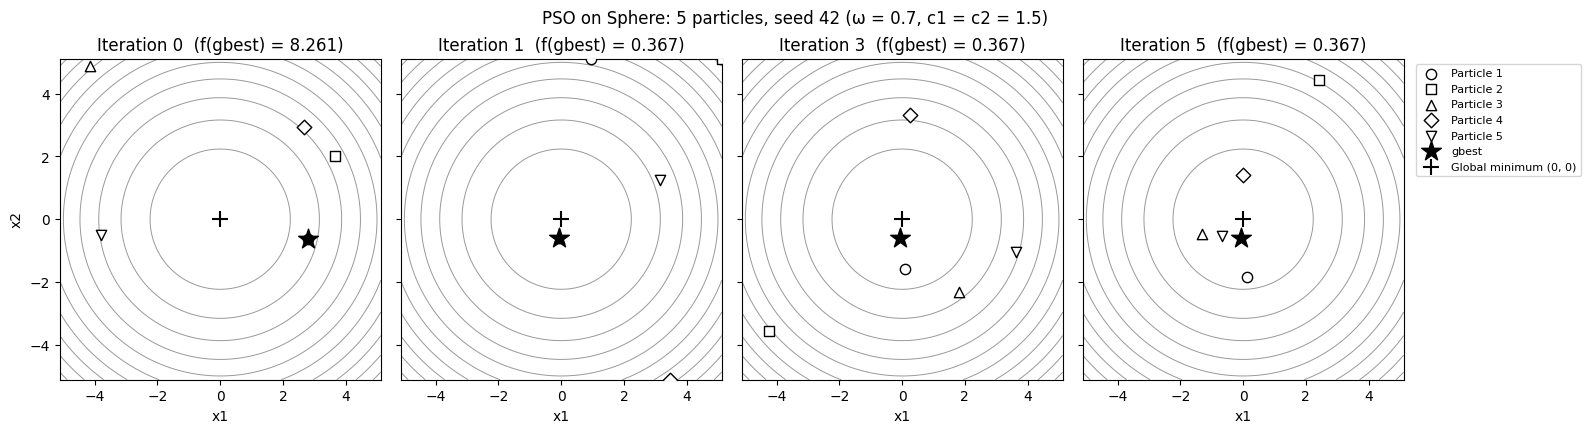

In [8]:
# Swarm positions on the Sphere contour at iterations 0, 1, 3 and 5
grid = np.linspace(*BOUNDS, 300)
GX, GY = np.meshgrid(grid, grid)
GZ = sphere(np.stack([GX, GY], axis=-1))

markers = ["o", "s", "^", "D", "v"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharex=True, sharey=True)
for ax, t in zip(axes, [0, 1, 3, 5]):
    s = sim["states"][t]
    ax.contour(GX, GY, GZ, levels=12, colors="0.6", linewidths=0.7)
    for i in range(5):
        ax.scatter(s["x"][i, 0], s["x"][i, 1], marker=markers[i], s=55,
                   facecolor="white", edgecolor="black", zorder=3, label=f"Particle {i + 1}")
    ax.scatter(*s["gbest"], marker="*", s=220, color="black", zorder=4, label="gbest")
    ax.scatter(0, 0, marker="+", s=120, color="black", zorder=4, label="Global minimum (0, 0)")
    ax.set_title(f"Iteration {t}  (f(gbest) = {s['gbest_f']:.3f})")
    ax.set_xlabel("x1")
    ax.set_aspect("equal")
axes[0].set_ylabel("x2")
axes[-1].legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8)
fig.suptitle("PSO on Sphere: 5 particles, seed 42 (ω = 0.7, c1 = c2 = 1.5)")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "fig_swarm_sphere.png"), dpi=150, bbox_inches="tight")
plt.show()

## 3. Inertia-weight experiment: 3 settings × 5 seeds (prompt 2.3)

In [9]:
results = run_experiments(FUNCTIONS, CONFIGS, SEEDS)
results.to_csv("results_pso.csv", index=False)
print(results.shape, "rows written to results_pso.csv")
results.head()

(3030, 9) rows written to results_pso.csv


,function,config,w,c1,c2,seed,iteration,evaluations,best_fitness
0,Sphere,A,0.4,1.5,1.5,0,0,20,2.8149
1,Sphere,A,0.4,1.5,1.5,0,1,40,0.2660
2,Sphere,A,0.4,1.5,1.5,0,2,60,0.2660
3,Sphere,A,0.4,1.5,1.5,0,3,80,0.1033
4,Sphere,A,0.4,1.5,1.5,0,4,100,0.0420


In [10]:
# Final best fitness (after 100 iterations = 2020 evaluations) per function and configuration
final = results[results.iteration == N_ITER]
summary = (final.groupby(["function", "config", "w"])["best_fitness"]
           .agg(mean="mean", std="std", best="min", worst="max").reset_index())
summary.to_csv("summary_pso.csv", index=False)
print(summary.to_string(index=False, float_format=lambda v: f"{v:.3e}"))

 function config         w      mean       std      best     worst
Rastrigin      A 4.000e-01 0.000e+00 0.000e+00 0.000e+00 0.000e+00
Rastrigin      B 7.000e-01 1.070e-06 2.345e-06 1.595e-11 5.264e-06
Rastrigin      C 9.000e-01 1.644e-01 2.827e-01 3.153e-03 6.685e-01
   Sphere      A 4.000e-01 8.813e-30 1.894e-29 1.573e-32 4.270e-29
   Sphere      B 7.000e-01 1.004e-12 1.250e-12 1.502e-15 2.433e-12
   Sphere      C 9.000e-01 3.598e-04 3.554e-04 4.847e-05 8.208e-04


In [11]:
# Final best fitness of every single run, for reference
pivot = final.pivot_table(index=["function", "config"], columns="seed", values="best_fitness")
print(pivot.to_string(float_format=lambda v: f"{v:.3e}"))

seed                     0         1         2         3         4
function  config                                                  
Rastrigin A      0.000e+00 0.000e+00 0.000e+00 0.000e+00 0.000e+00
          B      1.570e-08 1.772e-09 5.264e-06 6.694e-08 1.595e-11
          C      6.685e-01 6.378e-02 5.143e-02 3.493e-02 3.153e-03
Sphere    A      3.994e-31 9.098e-31 4.270e-29 1.573e-32 4.586e-32
          B      1.502e-15 2.645e-13 2.303e-12 1.977e-14 2.433e-12
          C      1.925e-04 6.584e-04 7.914e-05 8.208e-04 4.847e-05


**Giải thích (VI):** bảng `summary` là kết quả cuối (vòng 100) gộp qua 5 seed: trung bình, độ lệch chuẩn (mẫu, ddof = 1), tốt nhất, tệ nhất. Bảng `pivot` liệt kê từng lần chạy để kiểm tra chéo với `results_pso.csv`. Chỉ có 5 seed nên trung bình và độ lệch chuẩn chỉ mang tính tham khảo.

**Lưu ý độ chính xác số (VI):** Rastrigin được tính bằng 20 + Σ(xᵢ² − 10cos 2πxᵢ), tức là trừ hai số gần 20 cho nhau. Sai số làm tròn của máy ở mức khoảng 1e-14, nên mọi giá trị Rastrigin nhỏ hơn khoảng 1e-13 (kể cả 0.000e+00 trong bảng) đều nên hiểu là "đã tới cực tiểu toàn cục", không so sánh tiếp được. Sphere không có phép trừ này nên các giá trị rất nhỏ của Sphere vẫn có nghĩa.

**Numerical note:** Rastrigin is computed as 20 + Σ(xᵢ² − 10 cos 2πxᵢ), a difference of two numbers close to 20, so values below about 1e-13 (including the exact zeros) are at floating-point resolution and mean "global minimum reached". On the log plots, zeros are drawn at 1e-16.

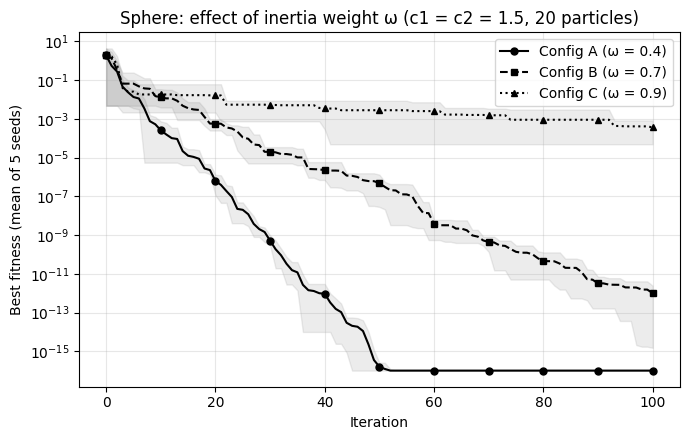

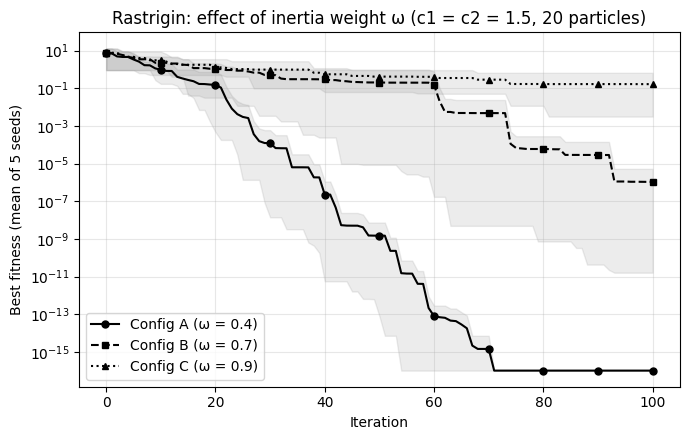

In [12]:
# Convergence plots: mean best fitness over 5 seeds, band = min..max, log scale
FLOOR = 1e-16   # values are floored for the log axis only; the CSV keeps the exact numbers
styles = {"A": ("-", "o"), "B": ("--", "s"), "C": (":", "^")}

for fname in FUNCTIONS:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for cname, w in CONFIGS.items():
        sub = results[(results.function == fname) & (results.config == cname)]
        g = sub.groupby("iteration")["best_fitness"]
        mean = g.mean().clip(lower=FLOOR)
        lo_ = g.min().clip(lower=FLOOR)
        hi_ = g.max().clip(lower=FLOOR)
        ls, mk = styles[cname]
        ax.plot(mean.index, mean.values, ls, color="black", marker=mk, markevery=10, markersize=5,
                label=f"Config {cname} (ω = {w})")
        ax.fill_between(mean.index, lo_.values, hi_.values, color="0.5", alpha=0.15)
    ax.set_yscale("log")
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Best fitness (mean of 5 seeds)")
    ax.set_title(f"{fname}: effect of inertia weight ω (c1 = c2 = 1.5, 20 particles)")
    ax.grid(True, which="major", alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, f"fig_omega_{fname.lower()}.png"), dpi=150)
    plt.show()

In [13]:
# Reproducibility check: re-run one combination and compare with the CSV
check = pso(rastrigin, w=CONFIGS["C"], seed=3)["history"]
csv_rows = results[(results.function == "Rastrigin") & (results.config == "C") & (results.seed == 3)]
assert np.allclose(check["best_fitness"].values, csv_rows["best_fitness"].values)
assert results.groupby(["function", "config", "seed"])["evaluations"].max().eq(2020).all()
print("Re-run matches results_pso.csv; every run used 2020 evaluations.")

Re-run matches results_pso.csv; every run used 2020 evaluations.


## 4. Sensitivity to the velocity limit v_max

The team default v_max = 10.24 is the domain width, following the rule V_max = X_max (Poli et al. 2007, Sects. 2.3–2.4). An earlier version of the experiments used the tighter limit v_max = 2.0 (about 20% of the domain width). This cell repeats the inertia sweep with v_max = 2.0, 5.12, 10.24 (the domain width, team default) and with no velocity clamp (initial velocities still drawn from ±10.24).

In [14]:
VMAX_VARIANTS = [("2.0", dict(vmax=2.0)), ("5.12", dict(vmax=5.12)),
                 ("10.24 (team)", dict(vmax=10.24)), ("none", dict(vmax=10.24, clamp=False))]
rows = []
for vname, kw in VMAX_VARIANTS:
    for fname, func in FUNCTIONS.items():
        for cname, w in CONFIGS.items():
            fin = [pso(func, w=w, seed=s, **kw)["best_f"] for s in SEEDS]
            rows.append({"vmax": vname, "function": fname, "config": cname, "w": w,
                         "mean": np.mean(fin), "std": np.std(fin, ddof=1), "best": min(fin), "worst": max(fin),
                         "runs_above_1e-3": sum(f > 1e-3 for f in fin)})
vmax_df = pd.DataFrame(rows)
vmax_df.to_csv("vmax_sensitivity.csv", index=False)
order = [v[0] for v in VMAX_VARIANTS]
print("Mean final best fitness (5 seeds):")
print(vmax_df.pivot_table(index=["function", "config"], columns="vmax", values="mean")[order]
      .to_string(float_format=lambda v: f"{v:.2e}"))
print("\nRuns ending above 1e-3 (out of 5):")
print(vmax_df.pivot_table(index=["function", "config"], columns="vmax", values="runs_above_1e-3")[order].to_string())

# The team setting must reproduce Table 4.3
team = vmax_df[vmax_df.vmax == "10.24 (team)"].set_index(["function", "config"])["mean"]
assert np.allclose(team.sort_index().values, summary.set_index(["function", "config"])["mean"].sort_index().values)

Mean final best fitness (5 seeds):
vmax                  2.0     5.12  10.24 (team)     none
function  config                                         
Rastrigin A      1.99e-01 1.99e-01      0.00e+00 0.00e+00
          B      2.08e-07 1.96e-08      1.07e-06 9.63e-09
          C      8.45e-03 4.43e-02      1.64e-01 6.74e-02
Sphere    A      5.45e-31 2.92e-30      8.81e-30 8.81e-30
          B      1.79e-13 5.78e-13      1.00e-12 1.26e-12
          C      4.16e-05 1.15e-04      3.60e-04 3.27e-04

Runs ending above 1e-3 (out of 5):
vmax              2.0  5.12  10.24 (team)  none
function  config                               
Rastrigin A       1.0   1.0           0.0   0.0
          B       0.0   0.0           0.0   0.0
          C       4.0   5.0           5.0   5.0
Sphere    A       0.0   0.0           0.0   0.0
          B       0.0   0.0           0.0   0.0
          C       0.0   0.0           0.0   1.0


**Giải thích (VI):** mặc định hiện tại là v_max = 10.24 (độ rộng miền). Với Sphere, thứ tự A < B < C giữ nguyên ở mọi v_max. Với Rastrigin ở v_max = 10.24 hoặc không giới hạn, cả 5 lần chạy ω = 0.4 đều về 0 nên ω = 0.4 tốt nhất, còn ω = 0.9 kém nhất. Khi v_max nhỏ hơn (2.0 hoặc 5.12), một lần chạy ω = 0.4 bị kẹt ở 0.995 nên ω = 0.7 tốt nhất trên Rastrigin. Vì vậy thứ hạng của ω trên Rastrigin phụ thuộc vào giới hạn vận tốc.